# Regional Labor Market Resilience — Raw Data Acquisition

Download original inputs for the **January 2010–December 2023** panel (counterfactual training ends **February 2020**). Run cells from top to bottom. Place this notebook in the repository `code/` folder and open the repository in VS Code. No transformations or models are run here.

In [25]:
%pip install requests pandas openpyxl matplotlib 

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 82.6 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 69.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 89.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Configuration
Set `DOWNLOAD_QCEW=False` for a quick test of the smaller files. Files already present are not overwritten unless `FORCE_DOWNLOAD=True`. The notebook uses project-relative paths.

In [2]:
DOWNLOAD_QCEW = True
FORCE_DOWNLOAD = False

### Set working directory

In [1]:
from pathlib import Path
import os

# Locate the Git repository root
current = Path.cwd().resolve()

if (current / ".git").exists():
    ROOT = current
elif (current.parent / ".git").exists():
    ROOT = current.parent
else:
    raise FileNotFoundError(
        "Cannot locate Git repository root. "
        "Open the repository folder in VS Code."
    )

# Set working directory to the repository root
os.chdir(ROOT)

# Define project directories
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "output"
CODE = ROOT / "code"
MANUSCRIPT = ROOT / "manuscript"

for folder in [RAW, PROCESSED, OUTPUT, CODE, MANUSCRIPT]:
    folder.mkdir(parents=True, exist_ok=True)

print("Repository root:", ROOT)
print("Working directory:", Path.cwd())

Repository root: C:\Directed Practicum\regional-labor-resilience
Working directory: C:\Directed Practicum\regional-labor-resilience


## Download utilities and source definitions

In [4]:
from __future__ import annotations
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlencode
import requests
import zipfile

ROOT = Path.cwd().parent if Path.cwd().name == 'code' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
SESSION = requests.Session()
SESSION.headers.update({'User-Agent': 'Academic research data downloader (Python requests)'})

ACS_FIELDS = [
    'NAME', 'B15003_001E', *[f'B15003_{n:03d}E' for n in range(22,26)],
    'B19013_001E', 'B23025_001E', 'B23025_002E', 'B23025_003E',
    'B23025_005E', 'B23025_007E',
]

def download(url: str, destination: Path, *, force=False):
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and not force:
        print(f'SKIP {destination.relative_to(ROOT)} (already exists)')
        return {'status': 'existing', 'path': str(destination.relative_to(ROOT)), 'url': url}
    temp = destination.with_name(destination.name + '.part')
    for attempt in range(1, 4):
        try:
            print(f'DOWNLOAD {destination.relative_to(ROOT)} (attempt {attempt})')
            with SESSION.get(url, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()
                with temp.open('wb') as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)
            if temp.stat().st_size == 0:
                raise ValueError('Empty response')
            temp.replace(destination)
            digest = hashlib.sha256()
            with destination.open('rb') as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b''):
                    digest.update(chunk)
            return {'status': 'downloaded', 'path': str(destination.relative_to(ROOT)),
                    'url': url, 'bytes': destination.stat().st_size,
                    'sha256': digest.hexdigest()}
        except (requests.RequestException, OSError, ValueError) as exc:
            print(f'  ERROR: {exc}')
            if attempt < 3:
                time.sleep(2 * attempt)
    return {'status': 'failed', 'path': str(destination.relative_to(ROOT)), 'url': url}



## Download raw inputs and write provenance manifest

The annual QCEW archives are large. Failed downloads are logged, and rerunning skips successful files.

In [5]:


QCEW_DIR = Path("data/raw/qcew")
QCEW_DIR.mkdir(parents=True, exist_ok=True)

for year in range(2010, 2024):
    url = (
        f"https://data.bls.gov/cew/data/files/{year}/csv/"
        f"{year}_qtrly_by_area.zip"
    )

    destination = QCEW_DIR / f"{year}_qtrly_by_area.zip"

    if destination.exists() and zipfile.is_zipfile(destination):
        print(f"SKIP {year}: valid archive already exists")
        continue

    print(f"Downloading QCEW {year}...")

    try:
        with requests.get(url, stream=True, timeout=(20, 180)) as response:
            response.raise_for_status()

            temporary = destination.with_suffix(".zip.part")

            with open(temporary, "wb") as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)

        if not zipfile.is_zipfile(temporary):
            temporary.unlink(missing_ok=True)
            raise ValueError("Downloaded file is not a valid ZIP archive")

        temporary.replace(destination)
        print(f"SUCCESS: {destination}")

    except (requests.RequestException, ValueError) as error:
        print(f"FAILED {year}: {error}")

    time.sleep(1)

print("QCEW download process complete.")

SKIP 2010: valid archive already exists
SKIP 2011: valid archive already exists
SKIP 2012: valid archive already exists
SKIP 2013: valid archive already exists
SKIP 2014: valid archive already exists
SKIP 2015: valid archive already exists
SKIP 2016: valid archive already exists
SKIP 2017: valid archive already exists
SKIP 2018: valid archive already exists
SKIP 2019: valid archive already exists
SKIP 2020: valid archive already exists
SKIP 2021: valid archive already exists
SKIP 2022: valid archive already exists
SKIP 2023: valid archive already exists
QCEW download process complete.


## Review acquisition results

Only proceed to the data audit after resolving failed downloads. **Important:** OEWS area definitions do not align exactly with all micropolitan CBSAs, and a teleworkability crosswalk is not yet included. Historical Connecticut geography and QCEW suppression must be checked in the processing notebook.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
import re
import json
from datetime import datetime, timezone

ROOT = Path.cwd()

# Support notebooks opened from either repository root or code/
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw" / "qcew"
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "output"

PROCESSED.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)

archives = {
    year: RAW / f"{year}_qtrly_by_area.zip"
    for year in range(2010, 2024)
}

for year, path in archives.items():
    assert path.is_file(), f"Missing archive: {path}"
    assert zipfile.is_zipfile(path), f"Invalid ZIP: {path}"

print("Project root:", ROOT)
print("Verified archives:", len(archives))

Project root: C:\Directed Practicum\regional-labor-resilience
Verified archives: 14


## Inspect Structure

In [7]:
with zipfile.ZipFile(archives[2019]) as z:
    members = [
        m for m in z.namelist()
        if m.lower().endswith(".csv")
    ]

    print("CSV members:", len(members))
    print("First 10 members:")
    for name in members[:10]:
        print(" ", name)

    with z.open(members[0]) as f:
        example = pd.read_csv(f, nrows=5, dtype=str)

display(example)
print("Columns:", example.columns.tolist())

CSV members: 4428
First 10 members:
  2019.q1-q4.by_area/2019.q1-q4 01000 Alabama -- Statewide.csv
  2019.q1-q4.by_area/2019.q1-q4 01001 Autauga County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01003 Baldwin County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01005 Barbour County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01007 Bibb County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01009 Blount County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01011 Bullock County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01013 Butler County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01015 Calhoun County, Alabama.csv
  2019.q1-q4.by_area/2019.q1-q4 01017 Chambers County, Alabama.csv


,area_fips,own_code,industry_code,agglvl_code,size_code,year,qtr,disclosure_code,area_title,own_title,...,oty_month3_emplvl_chg,oty_month3_emplvl_pct_chg,oty_total_qtrly_wages_chg,oty_total_qtrly_wages_pct_chg,oty_taxable_qtrly_wages_chg,oty_taxable_qtrly_wages_pct_chg,oty_qtrly_contributions_chg,oty_qtrly_contributions_pct_chg,oty_avg_wkly_wage_chg,oty_avg_wkly_wage_pct_chg
0,01000,0,10,50,0,2019,1,NaN,Alabama -- Statewide,Total Covered,...,30224,1.6,1004646638,4.3,319152401,3.3,-5218776,-4.2,23,2.5
1,01000,0,10,50,0,2019,2,NaN,Alabama -- Statewide,Total Covered,...,25422,1.3,1068279087,4.7,-1684546,-0.1,-1855969,-5.4,29,3.3
2,01000,0,10,50,0,2019,3,NaN,Alabama -- Statewide,Total Covered,...,24011,1.2,1194973500,5.3,26974692,1.6,-1511807,-6.3,34,3.8
3,01000,0,10,50,0,2019,4,NaN,Alabama -- Statewide,Total Covered,...,22496,1.1,892902530,3.6,1763492,0.1,-2540857,-11.0,24,2.5
4,01000,1,10,51,0,2019,1,NaN,Alabama -- Statewide,Federal Government,...,921,1.8,54267702,5.2,0,0.0,0,0.0,51,3.3


Columns: ['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'size_code', 'year', 'qtr', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'agglvl_title', 'size_title', 'qtrly_estabs_count', 'month1_emplvl', 'month2_emplvl', 'month3_emplvl', 'total_qtrly_wages', 'taxable_qtrly_wages', 'qtrly_contributions', 'avg_wkly_wage', 'lq_disclosure_code', 'lq_qtrly_estabs_count', 'lq_month1_emplvl', 'lq_month2_emplvl', 'lq_month3_emplvl', 'lq_total_qtrly_wages', 'lq_taxable_qtrly_wages', 'lq_qtrly_contributions', 'lq_avg_wkly_wage', 'oty_disclosure_code', 'oty_qtrly_estabs_count_chg', 'oty_qtrly_estabs_count_pct_chg', 'oty_month1_emplvl_chg', 'oty_month1_emplvl_pct_chg', 'oty_month2_emplvl_chg', 'oty_month2_emplvl_pct_chg', 'oty_month3_emplvl_chg', 'oty_month3_emplvl_pct_chg', 'oty_total_qtrly_wages_chg', 'oty_total_qtrly_wages_pct_chg', 'oty_taxable_qtrly_wages_chg', 'oty_taxable_qtrly_wages_pct_chg', 'oty_qtrly_contributions_chg', 'oty_qtrly_contributions_pct_chg', 'oty_avg

## Extract Total Monthly Employment Count

In [8]:
EMPLOYMENT_COLUMNS = [
    "area_fips", "own_code", "industry_code",
    "year", "qtr", "disclosure_code",
    "month1_emplvl", "month2_emplvl", "month3_emplvl"
]

def extract_county_employment(year, archive_path):
    frames = []

    with zipfile.ZipFile(archive_path) as z:
        members = [
            m for m in z.namelist()
            if m.lower().endswith(".csv")
        ]

        for member in members:
            with z.open(member) as f:
                df = pd.read_csv(
                    f,
                    dtype=str,
                    usecols=lambda c: c in EMPLOYMENT_COLUMNS,
                    low_memory=False
                )

            required = set(EMPLOYMENT_COLUMNS)
            if not required.issubset(df.columns):
                raise ValueError(
                    f"Unexpected layout in {member}: "
                    f"{required - set(df.columns)}"
                )

            for col in ["area_fips", "own_code", "industry_code"]:
                df[col] = df[col].str.strip()

            # Five-digit county FIPS, excluding state totals.
            county = df["area_fips"].str.fullmatch(r"\d{5}", na=False)
            county &= ~df["area_fips"].str.endswith("000", na=False)

            df = df.loc[
                county
                & df["own_code"].eq("0")
                & df["industry_code"].eq("10")
            ].copy()

            if not df.empty:
                frames.append(df)

    if not frames:
        raise ValueError(f"No county employment records for {year}")

    result = pd.concat(frames, ignore_index=True)

    if not result["year"].eq(str(year)).all():
        raise ValueError(f"Year mismatch in archive {year}")

    return result


annual_raw = {}

for year, archive in archives.items():
    print(f"Processing {year}...", flush=True)

    df = extract_county_employment(year, archive)

    annual_raw[year] = df

    print(
        f"  {len(df):,} quarterly county records; "
        f"{df['area_fips'].nunique():,} geographic codes"
    )

Processing 2010...
  13,088 quarterly county records; 3,272 geographic codes
Processing 2011...
  13,088 quarterly county records; 3,272 geographic codes
Processing 2012...
  13,092 quarterly county records; 3,273 geographic codes
Processing 2013...
  13,088 quarterly county records; 3,272 geographic codes
Processing 2014...
  13,084 quarterly county records; 3,271 geographic codes
Processing 2015...
  13,096 quarterly county records; 3,274 geographic codes
Processing 2016...
  13,084 quarterly county records; 3,271 geographic codes
Processing 2017...
  13,088 quarterly county records; 3,272 geographic codes
Processing 2018...
  13,092 quarterly county records; 3,273 geographic codes
Processing 2019...
  13,092 quarterly county records; 3,273 geographic codes
Processing 2020...
  13,096 quarterly county records; 3,274 geographic codes
Processing 2021...
  13,096 quarterly county records; 3,274 geographic codes
Processing 2022...
  13,096 quarterly county records; 3,274 geographic codes

### Convert quarterly records to monthly observations

In [9]:
monthly_parts = []

for year, df in annual_raw.items():
    df = df.copy()

    df["qtr"] = pd.to_numeric(df["qtr"], errors="coerce")

    for month_in_quarter in (1, 2, 3):
        part = df[
            ["area_fips", "year", "qtr",
             "disclosure_code", f"month{month_in_quarter}_emplvl"]
        ].copy()

        part = part.rename(columns={
            "area_fips": "county_fips",
            f"month{month_in_quarter}_emplvl": "employment"
        })

        part["month"] = (
            (part["qtr"] - 1) * 3 + month_in_quarter
        )

        part["date"] = pd.to_datetime(
            dict(
                year=pd.to_numeric(part["year"]),
                month=part["month"],
                day=1
            ),
            errors="coerce"
        )

        part["employment"] = pd.to_numeric(
            part["employment"], errors="coerce"
        )

        part["suppressed"] = (
            part["disclosure_code"]
            .fillna("")
            .str.strip()
            .eq("N")
        )

        # Never interpret a suppressed observation as zero.
        part.loc[part["suppressed"], "employment"] = np.nan

        monthly_parts.append(
            part[["county_fips", "date",
                  "employment", "suppressed"]]
        )

county_monthly = pd.concat(monthly_parts, ignore_index=True)

county_monthly = county_monthly.sort_values(
    ["county_fips", "date"]
).reset_index(drop=True)

display(county_monthly.head(12))

,county_fips,date,employment,suppressed
0,01001,2010-01-01,10527.0,False
1,01001,2010-02-01,10628.0,False
2,01001,2010-03-01,10693.0,False
3,01001,2010-04-01,10684.0,False
4,01001,2010-05-01,10791.0,False
5,01001,2010-06-01,10764.0,False
6,01001,2010-07-01,10599.0,False
7,01001,2010-08-01,10645.0,False
8,01001,2010-09-01,10713.0,False
9,01001,2010-10-01,10712.0,False


### Audit duplicates, missingness, and coverage

In [10]:
duplicates = county_monthly.duplicated(
    ["county_fips", "date"], keep=False
)

duplicate_records = county_monthly.loc[duplicates].copy()

print("Duplicate county-month rows:", len(duplicate_records))

if not duplicate_records.empty:
    display(duplicate_records.head(20))
    raise ValueError(
        "Duplicate county-month records found. "
        "Investigate before continuing."
    )

expected_dates = pd.date_range(
    "2010-01-01", "2023-12-01", freq="MS"
)

counties = sorted(county_monthly["county_fips"].unique())

complete_index = pd.MultiIndex.from_product(
    [counties, expected_dates],
    names=["county_fips", "date"]
)

county_panel = (
    county_monthly
    .set_index(["county_fips", "date"])
    .reindex(complete_index)
    .reset_index()
)

county_panel["record_missing"] = (
    ~pd.MultiIndex.from_frame(
        county_panel[["county_fips", "date"]]
    ).isin(
        pd.MultiIndex.from_frame(
            county_monthly[["county_fips", "date"]]
        )
    )
)

county_panel["suppressed"] = (
    county_panel["suppressed"].fillna(False).astype(bool)
)

county_panel["employment_missing"] = (
    county_panel["employment"].isna()
)

audit = (
    county_panel.groupby("county_fips")
    .agg(
        months_expected=("date", "size"),
        months_missing=("employment_missing", "sum"),
        records_absent=("record_missing", "sum"),
        months_suppressed=("suppressed", "sum"),
        mean_employment=("employment", "mean")
    )
    .reset_index()
)

print("County geographic codes:", len(audit))
print("Expected months per county:", len(expected_dates))
print("Missing employment observations:",
      county_panel["employment_missing"].sum())

display(audit.describe(include="all"))
display(
    audit.sort_values("months_missing", ascending=False).head(20)
)

Duplicate county-month rows: 0
County geographic codes: 3278
Expected months per county: 168
Missing employment observations: 966


,county_fips,months_expected,months_missing,records_absent,months_suppressed,mean_employment
count,3278,3278.0,3278.000000,3278.000000,3278.000000,3.278000e+03
unique,3278,NaN,NaN,NaN,NaN,NaN
top,01001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,168.0,0.294692,0.267236,0.027456,4.310968e+04
std,NaN,0.0,5.170021,5.036998,0.523343,1.522521e+05
min,NaN,168.0,0.000000,0.000000,0.000000,4.853846e+01
25%,NaN,168.0,0.000000,0.000000,0.000000,3.092964e+03
50%,NaN,168.0,0.000000,0.000000,0.000000,8.139137e+03
75%,NaN,168.0,0.000000,0.000000,0.000000,2.417812e+04


,county_fips,months_expected,months_missing,records_absent,months_suppressed,mean_employment
73,02063,168,120,120,0,3539.770833
74,02066,168,120,120,0,1020.250000
2964,51515,168,120,120,0,3175.250000
96,02270,168,96,96,0,2104.194444
2461,46113,168,96,96,0,3349.513889
905,19999,168,90,72,18,5008.217949
331,11999,168,90,84,6,48.538462
84,02158,168,60,60,0,2030.046296
2455,46102,168,60,60,0,3629.851852
95,02261,168,48,48,0,4759.108333


### Save to CSV

In [11]:
county_panel.to_csv(
    PROCESSED / "qcew_county_monthly_2010_2023.csv",
    index=False
)

audit.to_csv(
    OUTPUT / "qcew_county_coverage_audit.csv",
    index=False
)

duplicate_records.to_csv(
    OUTPUT / "qcew_duplicate_records.csv",
    index=False
)

summary = {
    "source": "BLS QCEW quarterly by area",
    "start": "2010-01",
    "end": "2023-12",
    "ownership_code": "0",
    "industry_code": "10",
    "geographic_codes": int(len(audit)),
    "monthly_rows": int(len(county_panel)),
    "missing_employment": int(
        county_panel["employment_missing"].sum()
    ),
    "suppressed_rows": int(
        county_panel["suppressed"].sum()
    ),
    "generated_utc": datetime.now(timezone.utc).isoformat()
}

with open(OUTPUT / "qcew_processing_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "source": "BLS QCEW quarterly by area",
  "start": "2010-01",
  "end": "2023-12",
  "ownership_code": "0",
  "industry_code": "10",
  "geographic_codes": 3278,
  "monthly_rows": 550704,
  "missing_employment": 966,
  "suppressed_rows": 90,
  "generated_utc": "2026-10-15T16:46:05.432982+00:00"
}


# Crosswalk Counties to 2023 OMB CBSA Delineations
## Import official OMB crosswalk file

In [12]:
from pathlib import Path
import requests
import hashlib
from datetime import datetime, timezone
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

GEO_DIR = ROOT / "data" / "raw" / "geography"
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "output"

for folder in (GEO_DIR, PROCESSED, OUTPUT):
    folder.mkdir(parents=True, exist_ok=True)

url = (
    "https://www2.census.gov/programs-surveys/"
    "metro-micro/geographies/reference-files/"
    "2023/delineation-files/list1_2023.xlsx"
)

destination = GEO_DIR / "list1_2023.xlsx"

if not destination.exists():
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    destination.write_bytes(response.content)

print("File:", destination)
print("Size:", destination.stat().st_size, "bytes")
print("SHA256:", hashlib.sha256(destination.read_bytes()).hexdigest())
print("Access checked:", datetime.now(timezone.utc).isoformat())

File: C:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience\data\raw\geography\list1_2023.xlsx
Size: 143798 bytes
SHA256: 952c4b1e78acbb54e6ec9412434b7602fedacbf021736351a63c181bdb753629
Access checked: 2026-10-15T16:46:09.957545+00:00


### Inspect

In [13]:
workbook = pd.ExcelFile(destination)

print("Sheets:", workbook.sheet_names)

for sheet in workbook.sheet_names:
    print(f"\n--- {sheet} ---")
    preview = pd.read_excel(
        destination,
        sheet_name=sheet,
        header=None,
        nrows=12
    )
    display(preview)

Sheets: ['List 1']

--- List 1 ---


,0,1,2,3,4,5,6,7,8,9,10,11
0,Table with row headers in column A and column ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"List 1. CORE BASED STATISTICAL AREAS (CBSAs), ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CBSA Code,Metropolitan Division Code,CSA Code,CBSA Title,Metropolitan/Micropolitan Statistical Area,Metropolitan Division Title,CSA Title,County/County Equivalent,State Name,FIPS State Code,FIPS County Code,Central/Outlying County
3,10100,NaN,NaN,"Aberdeen, SD",Micropolitan Statistical Area,NaN,NaN,Brown County,South Dakota,46,013,Central
4,10100,NaN,NaN,"Aberdeen, SD",Micropolitan Statistical Area,NaN,NaN,Edmunds County,South Dakota,46,045,Outlying
5,10140,NaN,NaN,"Aberdeen, WA",Micropolitan Statistical Area,NaN,NaN,Grays Harbor County,Washington,53,027,Central
6,10180,NaN,101,"Abilene, TX",Metropolitan Statistical Area,NaN,"Abilene-Sweetwater, TX",Callahan County,Texas,48,059,Outlying
7,10180,NaN,101,"Abilene, TX",Metropolitan Statistical Area,NaN,"Abilene-Sweetwater, TX",Jones County,Texas,48,253,Outlying
8,10180,NaN,101,"Abilene, TX",Metropolitan Statistical Area,NaN,"Abilene-Sweetwater, TX",Taylor County,Texas,48,441,Central
9,10220,NaN,NaN,"Ada, OK",Micropolitan Statistical Area,NaN,NaN,Pontotoc County,Oklahoma,40,123,Central


### Construct County-CBSA Crosswalk

In [14]:
import re

raw = pd.read_excel(
    destination,
    sheet_name=workbook.sheet_names[0],
    header=None,
    dtype=str
)

def clean_label(value):
    return re.sub(
        r"\s+", " ",
        str(value).strip().lower()
    )

header_index = None

for i in range(min(25, len(raw))):
    labels = [clean_label(v) for v in raw.iloc[i]]
    if (
        any("cbsa code" in v for v in labels)
        and any("fips" in v and "state" in v for v in labels)
        and any("fips" in v and "county" in v for v in labels)
    ):
        header_index = i
        break

if header_index is None:
    raise ValueError(
        "Could not identify crosswalk headers. "
        "Inspect the previous cell's output."
    )

columns = [
    str(v).strip()
    for v in raw.iloc[header_index]
]

crosswalk_raw = raw.iloc[header_index + 1:].copy()
crosswalk_raw.columns = columns

def find_column(*terms):
    for col in crosswalk_raw.columns:
        label = clean_label(col)
        if all(term in label for term in terms):
            return col
    raise KeyError(f"Missing column containing: {terms}")

cbsa_col = find_column("cbsa", "code")
state_col = find_column("fips", "state")
county_col = find_column("fips", "county")
type_col = find_column("metropolitan", "micropolitan")

crosswalk = pd.DataFrame({
    "cbsa_code": crosswalk_raw[cbsa_col],
    "state_fips": crosswalk_raw[state_col],
    "county_code": crosswalk_raw[county_col],
    "cbsa_type": crosswalk_raw[type_col]
})

def normalize_code(series, width):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(width)
    )

crosswalk["cbsa_code"] = normalize_code(
    crosswalk["cbsa_code"], 5
)

crosswalk["state_fips"] = normalize_code(
    crosswalk["state_fips"], 2
)

crosswalk["county_code"] = normalize_code(
    crosswalk["county_code"], 3
)

crosswalk["county_fips"] = (
    crosswalk["state_fips"] +
    crosswalk["county_code"]
)

crosswalk = crosswalk[
    crosswalk["cbsa_code"].str.fullmatch(r"\d{5}", na=False)
    & crosswalk["county_fips"].str.fullmatch(r"\d{5}", na=False)
].copy()

crosswalk = crosswalk[
    crosswalk["cbsa_type"].str.contains(
        "Metropolitan|Micropolitan",
        case=False,
        na=False
    )
]

crosswalk = crosswalk.drop_duplicates(
    ["cbsa_code", "county_fips"]
)

# A county should not belong to multiple CBSAs.
conflicts = crosswalk.groupby("county_fips")["cbsa_code"].nunique()

assert conflicts.max() <= 1, (
    "County assigned to multiple CBSAs; inspect crosswalk."
)

crosswalk.to_csv(
    PROCESSED / "county_cbsa_crosswalk_2023.csv",
    index=False
)

print("CBSAs:", crosswalk["cbsa_code"].nunique())
print("Counties:", crosswalk["county_fips"].nunique())

display(crosswalk.head(10))

CBSAs: 935
Counties: 1915


,cbsa_code,state_fips,county_code,cbsa_type,county_fips
3,10100,46,013,Micropolitan Statistical Area,46013
4,10100,46,045,Micropolitan Statistical Area,46045
5,10140,53,027,Micropolitan Statistical Area,53027
6,10180,48,059,Metropolitan Statistical Area,48059
7,10180,48,253,Metropolitan Statistical Area,48253
8,10180,48,441,Metropolitan Statistical Area,48441
9,10220,40,123,Micropolitan Statistical Area,40123
10,10300,26,091,Micropolitan Statistical Area,26091
11,10380,72,003,Metropolitan Statistical Area,72003
12,10380,72,005,Metropolitan Statistical Area,72005


### QCEW/Crosswalk Merge

In [15]:
county_panel = pd.read_csv(
    PROCESSED / "qcew_county_monthly_2010_2023.csv",
    dtype={"county_fips": str},
    parse_dates=["date"]
)

county_panel["county_fips"] = (
    county_panel["county_fips"].str.zfill(5)
)

merged = county_panel.merge(
    crosswalk[[
        "county_fips", "cbsa_code", "cbsa_type"
    ]],
    on="county_fips",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Total county-month rows:", len(merged))
print("Rows mapped to a CBSA:",
      (merged["_merge"] == "both").sum())
print("Rows outside the crosswalk:",
      (merged["_merge"] == "left_only").sum())

unmatched = (
    merged.loc[
        merged["_merge"] == "left_only",
        ["county_fips"]
    ]
    .drop_duplicates()
    .sort_values("county_fips")
)

display(unmatched.head(30))

merged.drop(columns="_merge").to_csv(
    PROCESSED / "qcew_county_cbsa_join_audit.csv",
    index=False
)

Total county-month rows: 550704
Rows mapped to a CBSA: 320040
Rows outside the crosswalk: 230664


,county_fips
840,01011
1008,01013
1512,01019
1848,01023
2016,01025
2184,01027
2352,01029
2856,01035
3192,01039
3360,01041


## Coverage Audit

In [16]:
import pandas as pd
import numpy as np

# Ensure geographic identifiers are strings
crosswalk["county_fips"] = (
    crosswalk["county_fips"].astype(str).str.zfill(5)
)

county_panel["county_fips"] = (
    county_panel["county_fips"].astype(str).str.zfill(5)
)

# All counties required for each CBSA
expected_counties = (
    crosswalk.groupby("cbsa_code")["county_fips"]
    .nunique()
    .rename("expected_counties")
)

# Match only counties included in the 2023 crosswalk
mapped = county_panel.merge(
    crosswalk[["county_fips", "cbsa_code", "cbsa_type"]],
    on="county_fips",
    how="inner",
    validate="many_to_one"
)

# Count valid employment observations per CBSA-month
coverage = (
    mapped.groupby(["cbsa_code", "date"])
    .agg(
        observed_counties=(
            "employment",
            lambda x: x.notna().sum()
        ),
        employment_sum=("employment", "sum")
    )
    .reset_index()
)

coverage = coverage.merge(
    expected_counties,
    on="cbsa_code",
    how="left"
)

coverage["coverage_ratio"] = (
    coverage["observed_counties"] /
    coverage["expected_counties"]
)

coverage["complete"] = (
    coverage["observed_counties"] ==
    coverage["expected_counties"]
)

# Missing counties must not be treated as zero employment.
coverage.loc[
    ~coverage["complete"], "employment_sum"
] = np.nan

display(coverage.head(12))

print(
    "Complete CBSA-month observations:",
    coverage["complete"].sum()
)

print(
    "Incomplete CBSA-month observations:",
    (~coverage["complete"]).sum()
)

,cbsa_code,date,observed_counties,employment_sum,expected_counties,coverage_ratio,complete
0,10100,2010-01-01,2,20377.0,2,1.0,True
1,10100,2010-02-01,2,20421.0,2,1.0,True
2,10100,2010-03-01,2,20644.0,2,1.0,True
3,10100,2010-04-01,2,21071.0,2,1.0,True
4,10100,2010-05-01,2,21462.0,2,1.0,True
5,10100,2010-06-01,2,21773.0,2,1.0,True
6,10100,2010-07-01,2,21397.0,2,1.0,True
7,10100,2010-08-01,2,21461.0,2,1.0,True
8,10100,2010-09-01,2,21460.0,2,1.0,True
9,10100,2010-10-01,2,21503.0,2,1.0,True


Complete CBSA-month observations: 155733
Incomplete CBSA-month observations: 171


### Incomplete Employment Histories

In [17]:
cbsa_audit = (
    coverage.groupby("cbsa_code")
    .agg(
        months_observed=("date", "nunique"),
        complete_months=("complete", "sum"),
        mean_coverage=("coverage_ratio", "mean"),
        minimum_coverage=("coverage_ratio", "min")
    )
    .reset_index()
)

cbsa_audit["incomplete_months"] = (
    168 - cbsa_audit["complete_months"]
)

cbsa_audit = cbsa_audit.sort_values(
    "incomplete_months",
    ascending=False
)

display(cbsa_audit.head(30))

print(
    "CBSAs with all 168 months complete:",
    (cbsa_audit["complete_months"] == 168).sum()
)

print(
    "CBSAs requiring investigation:",
    (cbsa_audit["complete_months"] < 168).sum()
)

cbsa_audit.to_csv(
    OUTPUT / "cbsa_coverage_audit_2023.csv",
    index=False
)

,cbsa_code,months_observed,complete_months,mean_coverage,minimum_coverage,incomplete_months
420,27980,168,0,0.500000,0.5,168
259,21220,168,165,0.991071,0.5,3
0,10100,168,168,1.000000,1.0,0
1,10140,168,168,1.000000,1.0,0
2,10180,168,168,1.000000,1.0,0
3,10220,168,168,1.000000,1.0,0
4,10300,168,168,1.000000,1.0,0
5,10380,168,168,1.000000,1.0,0
6,10420,168,168,1.000000,1.0,0
7,10460,168,168,1.000000,1.0,0


CBSAs with all 168 months complete: 926
CBSAs requiring investigation: 2


### Directly audit Connecticut Planning Region Change

In [18]:
ct_crosswalk = crosswalk[
    crosswalk["state_fips"] == "09"
].copy()

ct_qcew = county_panel[
    county_panel["county_fips"].str.startswith("09")
].copy()

print("Connecticut counties in 2023 crosswalk:")
display(
    ct_crosswalk[
        ["county_fips", "cbsa_code", "cbsa_type"]
    ].drop_duplicates()
)

print("Connecticut geographic codes in QCEW:")
display(
    ct_qcew[["county_fips"]]
    .drop_duplicates()
    .sort_values("county_fips")
)

Connecticut counties in 2023 crosswalk:


,county_fips,cbsa_code,cbsa_type
255,09120,14860,Metropolitan Statistical Area
256,09190,14860,Metropolitan Statistical Area
728,09110,25540,Metropolitan Statistical Area
729,09130,25540,Metropolitan Statistical Area
1210,09170,35300,Metropolitan Statistical Area
1256,09180,35980,Metropolitan Statistical Area
1414,09150,39480,Micropolitan Statistical Area
1741,09160,45860,Micropolitan Statistical Area
1853,09140,47930,Metropolitan Statistical Area


Connecticut geographic codes in QCEW:


,county_fips
53256,09001
53424,09003
53592,09005
53760,09007
53928,09009
54096,09011
54264,09013
54432,09015
54600,09999


### Include all 935 CBSA's in Audit

In [19]:
import pandas as pd
import numpy as np

dates = pd.date_range(
    "2010-01-01",
    "2023-12-01",
    freq="MS"
)

cbsa_codes = sorted(crosswalk["cbsa_code"].unique())

full_index = pd.MultiIndex.from_product(
    [cbsa_codes, dates],
    names=["cbsa_code", "date"]
)

coverage_full = (
    coverage
    .set_index(["cbsa_code", "date"])
    .reindex(full_index)
    .reset_index()
)

expected = (
    crosswalk.groupby("cbsa_code")["county_fips"]
    .nunique()
    .rename("expected_counties")
)

coverage_full = coverage_full.drop(
    columns=["expected_counties"]
).merge(
    expected,
    on="cbsa_code",
    how="left"
)

coverage_full["observed_counties"] = (
    coverage_full["observed_counties"].fillna(0)
)

coverage_full["coverage_ratio"] = (
    coverage_full["observed_counties"]
    / coverage_full["expected_counties"]
)

coverage_full["complete"] = (
    coverage_full["observed_counties"]
    == coverage_full["expected_counties"]
)

coverage_full.loc[
    ~coverage_full["complete"],
    "employment_sum"
] = np.nan

cbsa_audit_full = (
    coverage_full.groupby("cbsa_code")
    .agg(
        complete_months=("complete", "sum"),
        mean_coverage=("coverage_ratio", "mean"),
        minimum_coverage=("coverage_ratio", "min")
    )
    .reset_index()
)

cbsa_audit_full["incomplete_months"] = (
    168 - cbsa_audit_full["complete_months"]
)

display(
    cbsa_audit_full[
        cbsa_audit_full["incomplete_months"] > 0
    ].sort_values("incomplete_months", ascending=False)
)

print("Total CBSAs:", len(cbsa_audit_full))
print(
    "Fully complete CBSAs:",
    (cbsa_audit_full["complete_months"] == 168).sum()
)
print(
    "Incomplete CBSAs:",
    (cbsa_audit_full["complete_months"] < 168).sum()
)

cbsa_audit_full.to_csv(
    OUTPUT / "cbsa_coverage_audit_full_2023.csv",
    index=False
)

,cbsa_code,complete_months,mean_coverage,minimum_coverage,incomplete_months
116,14860,0,0.000000,0.0,168
362,25540,0,0.000000,0.0,168
422,27980,0,0.500000,0.5,168
600,35300,0,0.000000,0.0,168
615,35980,0,0.000000,0.0,168
847,45860,0,0.000000,0.0,168
695,39480,0,0.000000,0.0,168
894,47930,0,0.000000,0.0,168
260,21220,165,0.991071,0.5,3


Total CBSAs: 935
Fully complete CBSAs: 926
Incomplete CBSAs: 9


### Spot Check 2 Problem Missing Data CBSA's

In [20]:
problem_codes = ["27980", "21220"]

problem_counties = crosswalk[
    crosswalk["cbsa_code"].isin(problem_codes)
][["cbsa_code", "county_fips", "cbsa_type"]]

display(problem_counties)

problem_detail = mapped[
    mapped["cbsa_code"].isin(problem_codes)
].copy()

missing_detail = problem_detail[
    problem_detail["employment"].isna()
]

display(
    missing_detail[
        ["cbsa_code", "county_fips", "date", "employment"]
    ].sort_values(["cbsa_code", "county_fips", "date"])
    .head(30)
)

,cbsa_code,county_fips,cbsa_type
571,21220,32007,Micropolitan Statistical Area
572,21220,32011,Micropolitan Statistical Area
860,27980,15005,Metropolitan Statistical Area
861,27980,15009,Metropolitan Statistical Area


,cbsa_code,county_fips,date,employment
163965,21220,32011,2023-10-01,NaN
163966,21220,32011,2023-11-01,NaN
163967,21220,32011,2023-12-01,NaN


### Provisional Monthly CBSA Panel

In [21]:
import pandas as pd
import numpy as np

# Ensure CBSA codes are consistent
coverage_full["cbsa_code"] = (
    coverage_full["cbsa_code"].astype(str).str.zfill(5)
)

crosswalk["cbsa_code"] = (
    crosswalk["cbsa_code"].astype(str).str.zfill(5)
)

# Retain CBSAs with all 168 months complete
eligible_codes = cbsa_audit_full.loc[
    cbsa_audit_full["complete_months"] == 168,
    "cbsa_code"
].astype(str).str.zfill(5)

cbsa_types = (
    crosswalk[["cbsa_code", "cbsa_type"]]
    .drop_duplicates()
)

cbsa_panel = (
    coverage_full[
        coverage_full["cbsa_code"].isin(eligible_codes)
    ][["cbsa_code", "date", "employment_sum"]]
    .rename(columns={"employment_sum": "employment"})
    .merge(
        cbsa_types,
        on="cbsa_code",
        how="left",
        validate="many_to_one"
    )
    .sort_values(["cbsa_code", "date"])
    .reset_index(drop=True)
)

cbsa_panel["date"] = pd.to_datetime(cbsa_panel["date"])

cbsa_panel["period"] = np.where(
    cbsa_panel["date"] <= pd.Timestamp("2020-02-01"),
    "pre_pandemic",
    "post_pandemic"
)

assert cbsa_panel["cbsa_code"].nunique() == 926
assert cbsa_panel.groupby("cbsa_code").size().eq(168).all()
assert cbsa_panel["employment"].notna().all()

cbsa_panel.to_csv(
    PROCESSED / "qcew_cbsa_monthly_2010_2023.csv",
    index=False
)

print("CBSAs:", cbsa_panel["cbsa_code"].nunique())
print("Monthly observations:", len(cbsa_panel))
print("Date range:", cbsa_panel["date"].min(),
      "to", cbsa_panel["date"].max())

display(cbsa_panel.head())

CBSAs: 926
Monthly observations: 155568
Date range: 2010-01-01 00:00:00 to 2023-12-01 00:00:00


,cbsa_code,date,employment,cbsa_type,period
0,10100,2010-01-01,20377.0,Micropolitan Statistical Area,pre_pandemic
1,10100,2010-02-01,20421.0,Micropolitan Statistical Area,pre_pandemic
2,10100,2010-03-01,20644.0,Micropolitan Statistical Area,pre_pandemic
3,10100,2010-04-01,21071.0,Micropolitan Statistical Area,pre_pandemic
4,10100,2010-05-01,21462.0,Micropolitan Statistical Area,pre_pandemic


### Record Sample Exclusions and Document Reason

In [22]:
excluded = cbsa_audit_full.loc[
    cbsa_audit_full["complete_months"] < 168
].copy()

excluded["reason"] = "Incomplete constituent-county employment"

ct_codes = set(
    crosswalk.loc[
        crosswalk["state_fips"] == "09",
        "cbsa_code"
    ]
)

excluded.loc[
    excluded["cbsa_code"].isin(ct_codes),
    "reason"
] = "2023 Connecticut planning-region geography mismatch"

excluded.to_csv(
    OUTPUT / "cbsa_sample_exclusions.csv",
    index=False
)

display(excluded[[
    "cbsa_code", "complete_months",
    "incomplete_months", "reason"
]])

,cbsa_code,complete_months,incomplete_months,reason
116,14860,0,168,2023 Connecticut planning-region geography mis...
260,21220,165,3,Incomplete constituent-county employment
362,25540,0,168,2023 Connecticut planning-region geography mis...
422,27980,0,168,Incomplete constituent-county employment
600,35300,0,168,2023 Connecticut planning-region geography mis...
615,35980,0,168,2023 Connecticut planning-region geography mis...
695,39480,0,168,2023 Connecticut planning-region geography mis...
847,45860,0,168,2023 Connecticut planning-region geography mis...
894,47930,0,168,2023 Connecticut planning-region geography mis...


## Sanity Check Employment Levels and Trends

In [23]:
cbsa_panel["employment_growth_yoy"] = (
    cbsa_panel.groupby("cbsa_code")["employment"]
    .pct_change(12, fill_method=None)
)

print("Employment distribution:")
display(cbsa_panel["employment"].describe())

print("Year-over-year growth distribution:")
display(
    cbsa_panel["employment_growth_yoy"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

extreme_changes = cbsa_panel.loc[
    cbsa_panel["employment_growth_yoy"].abs() > 0.50
]

print("Observations with >50% annual change:",
      len(extreme_changes))

display(
    extreme_changes[
        ["cbsa_code", "date", "employment",
         "employment_growth_yoy"]
    ].head(25)
)

Employment distribution:


count    1.555680e+05
mean     1.411171e+05
std      4.896358e+05
min      2.574000e+03
25%      1.526000e+04
50%      2.808450e+04
75%      7.496675e+04
max      9.454987e+06
Name: employment, dtype: float64

Year-over-year growth distribution:


count    144456.000000
mean          0.007619
std           0.038152
min          -0.384985
1%           -0.120762
5%           -0.054461
95%           0.054235
99%           0.102547
max           0.609079
Name: employment_growth_yoy, dtype: float64

Observations with >50% annual change: 15


,cbsa_code,date,employment,employment_growth_yoy
18951,14720,2021-04-01,24229.0,0.565484
43311,21140,2021-04-01,134834.0,0.561302
98751,34880,2021-04-01,6380.0,0.609079
102951,36180,2021-04-01,22993.0,0.507441
151722,48780,2011-07-01,24078.0,0.501590
151724,48780,2011-09-01,25792.0,0.508304
151725,48780,2011-10-01,26539.0,0.501160
151726,48780,2011-11-01,27932.0,0.554541
151727,48780,2011-12-01,29135.0,0.563875
151728,48780,2012-01-01,29833.0,0.524659


### CBSA 48780 Experiences large employment changes in 2011 and 2012, directly investigating

CBSA 48780 employment history:


,date,employment,employment_growth_yoy
151704,2010-01-01,13540.0,NaN
151705,2010-02-01,13959.0,NaN
151706,2010-03-01,14444.0,NaN
151707,2010-04-01,15004.0,NaN
151708,2010-05-01,15384.0,NaN
151709,2010-06-01,15926.0,NaN
151710,2010-07-01,16035.0,NaN
151711,2010-08-01,16502.0,NaN
151712,2010-09-01,17100.0,NaN
151713,2010-10-01,17679.0,NaN


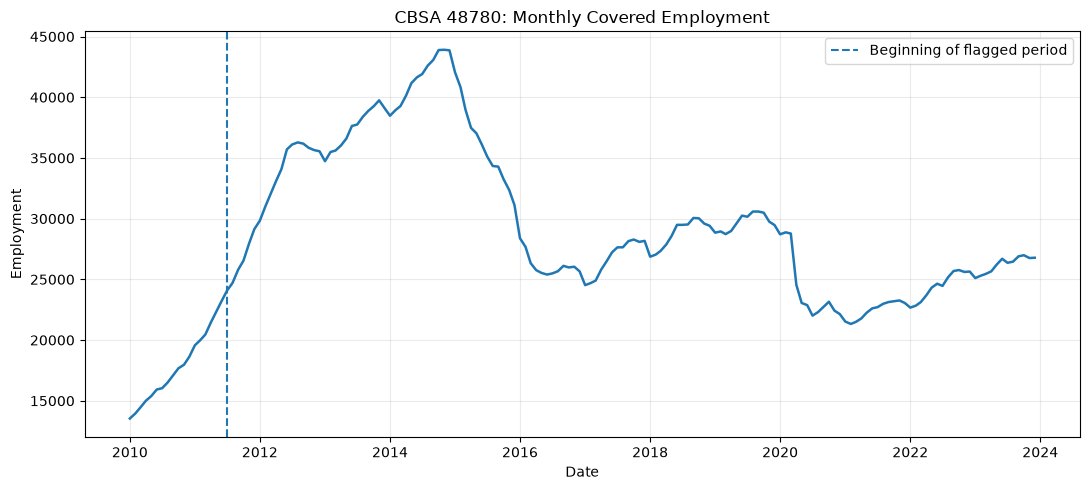

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

target = cbsa_panel[
    cbsa_panel["cbsa_code"] == "48780"
].copy()

print("CBSA 48780 employment history:")

display(
    target.loc[
        target["date"].between("2010-01-01", "2013-12-01"),
        ["date", "employment", "employment_growth_yoy"]
    ]
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    target["date"],
    target["employment"],
    linewidth=1.8
)

ax.axvline(
    pd.Timestamp("2011-07-01"),
    linestyle="--",
    label="Beginning of flagged period"
)

ax.set(
    title="CBSA 48780: Monthly Covered Employment",
    xlabel="Date",
    ylabel="Employment"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [27]:
counties_48780 = crosswalk.loc[
    crosswalk["cbsa_code"] == "48780",
    "county_fips"
].tolist()

print("Constituent counties:", counties_48780)

county_detail = county_panel[
    county_panel["county_fips"].isin(counties_48780)
    & county_panel["date"].between(
        "2010-01-01", "2013-12-01"
    )
].copy()

display(
    county_detail.pivot(
        index="date",
        columns="county_fips",
        values="employment"
    )
)

Constituent counties: ['38105']


county_fips,38105
date,
2010-01-01,13540.0
2010-02-01,13959.0
2010-03-01,14444.0
2010-04-01,15004.0
2010-05-01,15384.0
2010-06-01,15926.0
2010-07-01,16035.0
2010-08-01,16502.0
2010-09-01,17100.0


### CBSA 48780 Retained
The underlying county-level results show that CBSA 48780 consists of county FIPS 38105, Williams County, North Dakota. Reviewing the data directly shows that employment growth is a sustained regional pattern rather than an isolated data error. 
The trajectory shown is also consistent with the economic expansion and subsequent contraction associated with oil development in western North Dakota in this time period, which may be a plausible economic explanation. 

For these reasons, CBSA 48780 will be retained in the panel data. 